#Import Libraries

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
import seaborn as sns
from sklearn.metrics import r2_score, mean_absolute_error
import matplotlib.pyplot as plt
from sklearn.metrics import PredictionErrorDisplay

#Investigating Dataset

In [ ]:
rides = pd.read_csv('https://raw.githubusercontent.com/gerberl/6G7V0015-2324/main/datasets/bike.csv')
rides.head(5)

,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,hum,windspeed,cnt,days_since_2011
0,WINTER,2011,JAN,NO HOLIDAY,SAT,NO WORKING DAY,MISTY,8.175849,80.5833,10.749882,985,0
1,WINTER,2011,JAN,NO HOLIDAY,SUN,NO WORKING DAY,MISTY,9.083466,69.6087,16.652113,801,1
2,WINTER,2011,JAN,NO HOLIDAY,MON,WORKING DAY,GOOD,1.229108,43.7273,16.636703,1349,2
3,WINTER,2011,JAN,NO HOLIDAY,TUE,WORKING DAY,GOOD,1.400000,59.0435,10.739832,1562,3
4,WINTER,2011,JAN,NO HOLIDAY,WED,WORKING DAY,GOOD,2.666979,43.6957,12.522300,1600,4


In [ ]:
rides.describe()

,yr,temp,hum,windspeed,cnt,days_since_2011
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,2011.500684,15.283085,62.789406,12.762576,4504.348837,365.000000
std,0.500342,8.603397,14.242910,5.192357,1937.211452,211.165812
min,2011.000000,-5.220871,0.000000,1.500244,22.000000,0.000000
25%,2011.000000,7.842925,52.000000,9.041650,3152.000000,182.500000
50%,2012.000000,15.421651,62.666700,12.125325,4548.000000,365.000000
75%,2012.000000,22.804575,73.020850,15.625371,5956.000000,547.500000
max,2012.000000,32.498349,97.250000,34.000021,8714.000000,730.000000


In [ ]:
rides.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   season           731 non-null    object 
 1   yr               731 non-null    int64  
 2   mnth             731 non-null    object 
 3   holiday          731 non-null    object 
 4   weekday          731 non-null    object 
 5   workingday       731 non-null    object 
 6   weathersit       731 non-null    object 
 7   temp             731 non-null    float64
 8   hum              731 non-null    float64
 9   windspeed        731 non-null    float64
 10  cnt              731 non-null    int64  
 11  days_since_2011  731 non-null    int64  
dtypes: float64(3), int64(3), object(6)
memory usage: 68.7+ KB


#Repair Column Names

A few columns have names that could be named better. Let's fix that.

In [ ]:
rides = rides.rename(columns={"yr": "year", "workingday": "is_working_day", "cnt": "bike_count", "weekday": "week_day", "weathersit": "weather_situation", "temp": "temperature", "hum": "humidity", "mnth": "month", "holiday": "has_holiday"})

#Identifying Inconsistencies

In [ ]:
rides.head(1)

,season,year,month,has_holiday,week_day,is_working_day,weather_situation,temperature,humidity,windspeed,bike_count,days_since_2011
0,WINTER,2011,JAN,NO HOLIDAY,SAT,NO WORKING DAY,MISTY,8.175849,80.5833,10.749882,985,0


What we can do first is look at the features that won't be treated nicely by the model such as strings and non-categorical and non-numeric values. Let's turn season, year, and month into categorical columns.

In [ ]:
rides["season"] = rides["season"].astype("category")
rides["year"] = rides["year"].astype("category")
rides["month"] = rides["month"].astype("category")

To do the same with `weather_situation` and `week_day`

In [ ]:
rides["weather_situation"] = rides["weather_situation"].astype("category")
rides["week_day"] = rides["week_day"].astype("category")

Now we have a few columns with string values that need boolean values such as `has_holiday` and `is_working_day`

In [ ]:
rides["has_holiday"].unique()

array(['NO HOLIDAY', 'HOLIDAY'], dtype=object)

In [ ]:
rides["has_holiday"] = rides["has_holiday"].map({"NO HOLIDAY": 0, "HOLIDAY": 1}).astype("bool")

In [ ]:
rides["is_working_day"].unique()

array(['NO WORKING DAY', 'WORKING DAY'], dtype=object)

In [ ]:
rides["is_working_day"] = rides["is_working_day"].map({"NO WORKING DAY": 0, "WORKING DAY": 1}).astype("bool")

Now we have a database that is ready to be cleaned and and prepared for model fitting and training.

In [ ]:
rides.head(3)

,season,year,month,has_holiday,week_day,is_working_day,weather_situation,temperature,humidity,windspeed,bike_count,days_since_2011
0,WINTER,2011,JAN,False,SAT,False,MISTY,8.175849,80.5833,10.749882,985,0
1,WINTER,2011,JAN,False,SUN,False,MISTY,9.083466,69.6087,16.652113,801,1
2,WINTER,2011,JAN,False,MON,True,GOOD,1.229108,43.7273,16.636703,1349,2


#Data Cleaning

It doesn't look like there are any missing values in the dataset. Let's go through and double check all the columns.

In [ ]:
rides.isna().sum()

,0
season,0
year,0
month,0
has_holiday,0
week_day,0
is_working_day,0
weather_situation,0
temperature,0
humidity,0
windspeed,0


In [ ]:
rides["season"].unique()

['WINTER', 'SPRING', 'SUMMER', 'FALL']
Categories (4, object): ['FALL', 'SPRING', 'SUMMER', 'WINTER']

In [ ]:
rides["bike_count"].max()

8714

Text(0.5, 1.0, 'Distribution of humidity values')

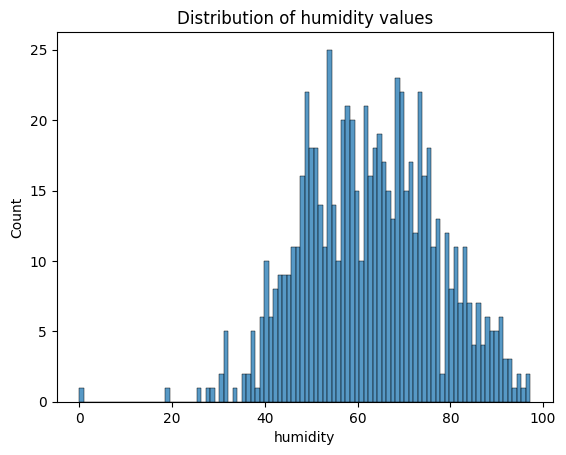

In [ ]:
sns.histplot(data=rides, x="humidity", bins=100).set_title("Distribution of humidity values")

We can't exactly have 0% humidity under natural conditions so why don't we deal with the outlier head-on. Mean is preferred in this case due to the distribution of the series.

Text(0.5, 1.0, 'Distribution of humidity values')

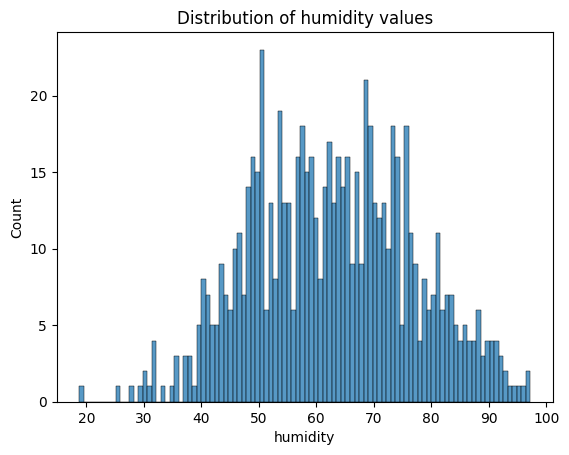

In [ ]:
humidity_mean = float(rides["humidity"].mean())
rides["humidity"] = rides["humidity"].replace(0.0, humidity_mean)
sns.histplot(data=rides, x="humidity", bins=100).set_title("Distribution of humidity values")

In [ ]:
rides["weather_situation"].unique()

['MISTY', 'GOOD', 'RAIN/SNOW/STORM']
Categories (3, object): ['GOOD', 'MISTY', 'RAIN/SNOW/STORM']

In [ ]:
rides.head(2)

,season,year,month,has_holiday,week_day,is_working_day,weather_situation,temperature,humidity,windspeed,bike_count,days_since_2011
0,WINTER,2011,JAN,False,SAT,False,MISTY,8.175849,80.5833,10.749882,985,0
1,WINTER,2011,JAN,False,SUN,False,MISTY,9.083466,69.6087,16.652113,801,1


#Model Preparation

In [ ]:
features = rides.drop(columns=["bike_count"])

In [ ]:
target = rides["bike_count"]

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(features, target, test_size=0.3, random_state=20261013)

Text(0.5, 1.0, 'Correlation of temperature to bike count: 0.63')

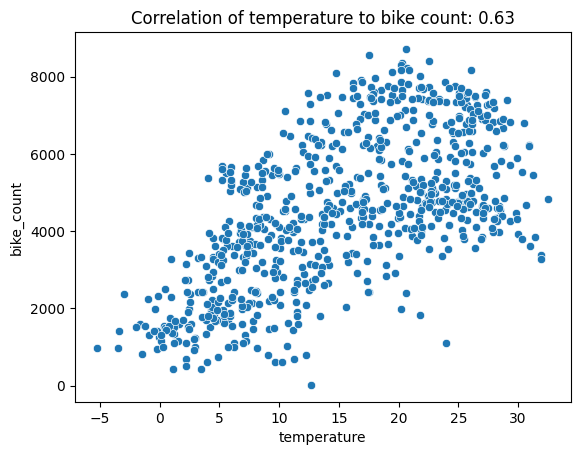

In [ ]:
sns.scatterplot(x=features["temperature"], y=target).set_title(f'Correlation of temperature to bike count: {round(features["temperature"].corr(target), 2)}')

#Initialise Regression Models (DTR & KNN)

In [ ]:
dt = DecisionTreeRegressor(max_depth=5)
knn = KNeighborsRegressor(n_neighbors=9, leaf_size=35)

### Encoding X Train and X Test

In [ ]:
x_train_encoded = pd.get_dummies(data=x_train)
x_test_encoded = pd.get_dummies(data=x_test)

### Fitting Models

In [ ]:
dt.fit(x_train_encoded, y_train)
dt_prediction = dt.predict(x_test_encoded)

In [ ]:
knn.fit(x_train_encoded, y_train)
knn_prediction = knn.predict(x_test_encoded)

#Retrieving R-Squared Score & Mean Absolute Error

In [ ]:
def getResults(y, pred):
  return {
      "r2": r2_score(y, pred),
      "mae": mean_absolute_error(y, pred),
      "mae_ratio": mean_absolute_error(y, pred) / (rides["bike_count"].max() - rides["bike_count"].min()) # MAE divided by range of "bike_count"
      }

DecisionTreeRegressor Results

In [ ]:
print(getResults(y_test, dt_prediction))

{'r2': 0.8055336892946832, 'mae': 624.0786722805262, 'mae_ratio': 0.07179920297751108}


KNeighborsRegressor Results

In [ ]:
print(getResults(y_test, knn_prediction))

{'r2': 0.8269436653627221, 'mae': 566.0404040404042, 'mae_ratio': 0.06512199770368203}


#Visualisation

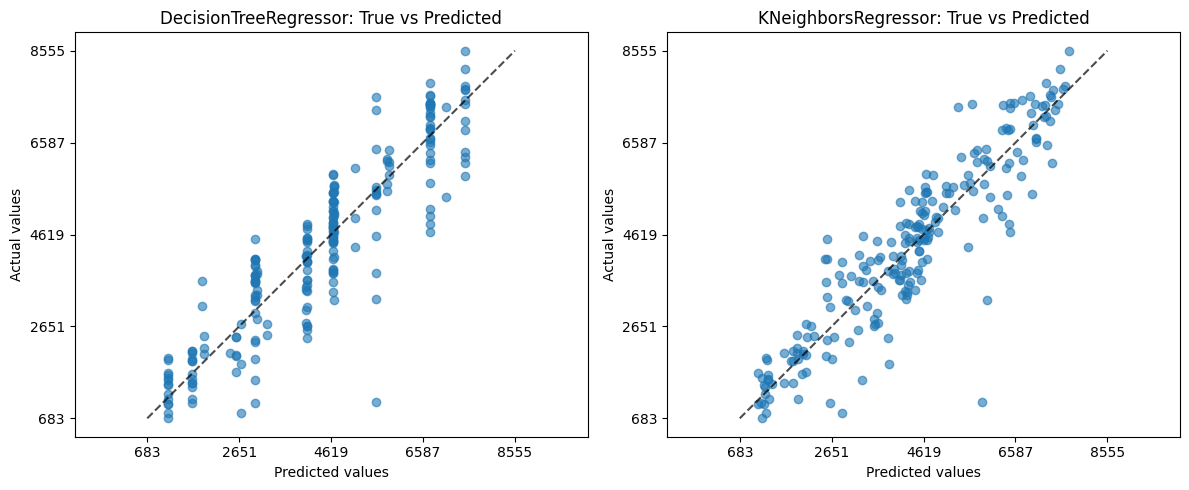

In [ ]:
fig, axs = plt.subplots(ncols=2, figsize=(12, 5))

# DecisionTreeRegressor Plot
PredictionErrorDisplay.from_predictions(
    y_test,
    dt_prediction,
    kind="actual_vs_predicted",
    ax=axs[0],
    scatter_kwargs={"alpha": 0.6}
)
axs[0].set_title("DecisionTreeRegressor: True vs Predicted")

# KNeighborsRegressor Plot
PredictionErrorDisplay.from_predictions(
    y_test,
    knn_prediction,
    kind="actual_vs_predicted",
    ax=axs[1],
    scatter_kwargs={"alpha": 0.6}
)
axs[1].set_title("KNeighborsRegressor: True vs Predicted")

plt.tight_layout()
plt.show()